In [1]:
import os
import random
import time
import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
from torchvision.transforms import v2
import timm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Фиксация seed для воспроизводимости
SEED = 42
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
# Ограничиваем потоки для стабильности на CPU, если GPU вдруг отключится
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используется устройство: {device}")

Используется устройство: cuda


In [2]:
VARIANT = 3
DATA_ROOT = "./data"

# Спецификация для Варианта 3 из таблицы методички
SPEC = {
    "name": "EuroSAT",
    "loader": "eurosat",
    "img_size": 64,
    "grayscale": False,
    "backbone": "mobilenetv2_100"
}

LR = 5e-4
EPOCHS = 20
DROPOUT = min(0.1 * VARIANT, 0.5)  # 0.3
BATCH_SIZE = 32

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

print(f"Вариант: {VARIANT} | Датасет: {SPEC['name']} | Backbone: {SPEC['backbone']}")
print(f"LR: {LR} | Epochs: {EPOCHS} | Dropout: {DROPOUT}")

Вариант: 3 | Датасет: EuroSAT | Backbone: mobilenetv2_100
LR: 0.0005 | Epochs: 20 | Dropout: 0.30000000000000004


In [3]:
class WithTransform(torch.utils.data.Dataset):
    def __init__(self, base, transform):
        self.base = base
        self.transform = transform
    def __len__(self):
        return len(self.base)
    def __getitem__(self, index):
        image, label = self.base[index]
        # EuroSAT в torchvision возвращает PIL Image, конвертируем в 3 канала если нужно
        if isinstance(image, np.ndarray):
            from PIL import Image
            image = Image.fromarray(image)
        return self.transform(image), label

def build_eval_transform(spec):
    ops = [v2.Resize((spec["img_size"], spec["img_size"]), antialias=True)]
    if spec["grayscale"]:
        ops.append(v2.Grayscale(num_output_channels=3))
    ops += [
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
    return v2.Compose(ops)

def build_train_transform(spec):
    ops = [v2.Resize((spec["img_size"], spec["img_size"]), antialias=True)]
    if spec["grayscale"]:
        ops.append(v2.Grayscale(num_output_channels=3))
    ops += [
        v2.RandomHorizontalFlip(),
        v2.RandAugment(num_ops=2, magnitude=9),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        v2.RandomErasing(p=0.25),
    ]
    return v2.Compose(ops)

# Загрузка EuroSAT
base_dataset = datasets.EuroSAT(DATA_ROOT, download=True)
n_val = n_test = int(0.15 * len(base_dataset))
n_train = len(base_dataset) - n_val - n_test
g = torch.Generator().manual_seed(SEED)
tr, va, te = random_split(base_dataset, [n_train, n_val, n_test], generator=g)

train_tf = build_train_transform(SPEC)
eval_tf = build_eval_transform(SPEC)

train_ds = WithTransform(tr, train_tf)
val_ds = WithTransform(va, eval_tf)
test_ds = WithTransform(te, eval_tf)
CLASS_NAMES = base_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

# Подвыборка для ускорения обучения (разрешено методичкой для local-first/Colab)
n_subset = min(len(train_ds), 4000)
g_sub = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(train_ds), generator=g_sub)[:n_subset]
train_ds = Subset(train_ds, idx.tolist())

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=2)

print(f"Классы ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"Размеры: train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}")

100%|██████████| 94.3M/94.3M [00:02<00:00, 43.4MB/s]


Классы (10): ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Размеры: train=4000, val=4050, test=4050


In [4]:
@torch.no_grad()
def evaluate(model, loader, loss_fn, num_classes):
    model.eval()
    total, correct, loss_sum = 0, 0, 0.0
    all_true, all_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        pred = logits.argmax(dim=1)
        loss_sum += loss.item() * yb.size(0)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        all_true.append(yb.cpu())
        all_pred.append(pred.cpu())

    y_true = torch.cat(all_true)
    y_pred = torch.cat(all_pred)
    f1s = []
    for c in range(num_classes):
        tp = ((y_pred == c) & (y_true == c)).sum().item()
        fp = ((y_pred == c) & (y_true != c)).sum().item()
        fn = ((y_pred != c) & (y_true == c)).sum().item()
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        f1s.append(2 * prec * rec / (prec + rec) if prec + rec else 0.0)

    return {"loss": loss_sum / total, "acc": correct / total, "macro_f1": sum(f1s) / len(f1s)}

def train_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total, correct, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return loss_sum / total, correct / total

def fit(model, train_loader, val_loader, epochs, lr, loss_fn=None):
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
    best_f1, best_state = -1.0, None

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_epoch(model, train_loader, loss_fn, optimizer)
        val = evaluate(model, val_loader, loss_fn, NUM_CLASSES)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(val["loss"])
        history["val_acc"].append(val["acc"])
        history["val_f1"].append(val["macro_f1"])

        if val["macro_f1"] > best_f1:
            best_f1 = val["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())

        print(f"epoch {epoch:02d} | train_loss {tr_loss:.4f} | val_loss {val['loss']:.4f} | val_acc {val['acc']:.4f} | val_f1 {val['macro_f1']:.4f}")

    if best_state is not None:
        model.load_state_dict(best_state)
    return history, best_f1

In [5]:
# Оригинальная CNN (Вариант 3)
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, kernel, padding=kernel//2, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        return self.pool(self.act(self.bn(self.conv(x))))

class CustomCNN(nn.Module):
    def __init__(self, variant, in_channels, num_classes, input_size, dropout):
        super().__init__()
        f1 = 16 * (variant + 1)  # Для варианта 3: 16 * 4 = 64
        f2 = f1 * 2              # 128
        f3 = f2 * 2              # 256
        k3 = max(1, min(variant + 2, input_size // 4)) # min(5, 16) = 5

        self.features = nn.Sequential(
            ConvBlock(in_channels, f1, 3),
            ConvBlock(f1, f2, 3),
            ConvBlock(f2, f3, k3),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(f3, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.gap(self.features(x)))

# Инициализация модели
set_seed()
custom_model = CustomCNN(VARIANT, 3, NUM_CLASSES, SPEC["img_size"], DROPOUT).to(device)
print(f"Параметров в оригинальной CNN: {sum(p.numel() for p in custom_model.parameters()):,}")

Параметров в оригинальной CNN: 995,530


epoch 01 | train_loss 1.8785 | val_loss 1.3266 | val_acc 0.5235 | val_f1 0.4735
epoch 02 | train_loss 1.5312 | val_loss 1.1094 | val_acc 0.5541 | val_f1 0.5052
epoch 03 | train_loss 1.3739 | val_loss 0.9515 | val_acc 0.6489 | val_f1 0.6287
epoch 04 | train_loss 1.2838 | val_loss 0.8739 | val_acc 0.6936 | val_f1 0.6655
epoch 05 | train_loss 1.2318 | val_loss 0.8867 | val_acc 0.6662 | val_f1 0.6399
epoch 06 | train_loss 1.1765 | val_loss 0.8274 | val_acc 0.6889 | val_f1 0.6701
epoch 07 | train_loss 1.1376 | val_loss 0.8154 | val_acc 0.7121 | val_f1 0.6879
epoch 08 | train_loss 1.1088 | val_loss 0.9108 | val_acc 0.6694 | val_f1 0.6569
epoch 09 | train_loss 1.0949 | val_loss 0.7927 | val_acc 0.7212 | val_f1 0.7115
epoch 10 | train_loss 1.0797 | val_loss 0.7583 | val_acc 0.7252 | val_f1 0.7087
epoch 11 | train_loss 1.0445 | val_loss 1.0163 | val_acc 0.6025 | val_f1 0.5792
epoch 12 | train_loss 0.9949 | val_loss 0.8108 | val_acc 0.6993 | val_f1 0.6845
epoch 13 | train_loss 0.9914 | val_loss 

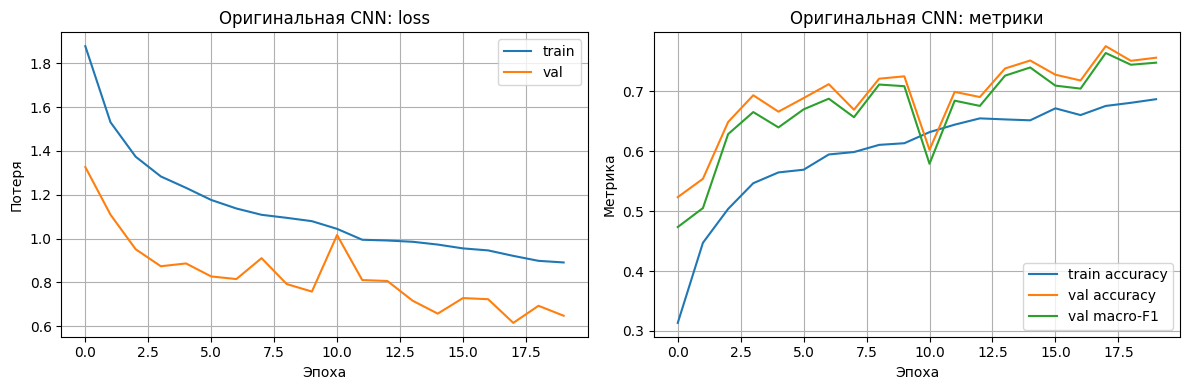

In [6]:
set_seed()
t0 = time.perf_counter()
hist_custom, best_f1_custom = fit(custom_model, train_loader, val_loader, EPOCHS, LR)
time_custom = time.perf_counter() - t0

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist_custom["train_loss"], label="train")
plt.plot(hist_custom["val_loss"], label="val")
plt.xlabel("Эпоха"); plt.ylabel("Потеря"); plt.title("Оригинальная CNN: loss"); plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(hist_custom["train_acc"], label="train accuracy")
plt.plot(hist_custom["val_acc"], label="val accuracy")
plt.plot(hist_custom["val_f1"], label="val macro-F1")
plt.xlabel("Эпоха"); plt.ylabel("Метрика"); plt.title("Оригинальная CNN: метрики"); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
import timm

class TransferModel(nn.Module):
    """Предобученный backbone (без классификационной головы) + новая голова."""
    def __init__(self, backbone, num_classes, variant):
        super().__init__()
        # Загружаем предобученный backbone без головы (num_classes=0)
        self.backbone = timm.create_model(backbone, pretrained=True, num_classes=0)
        feat_dim = self.backbone.num_features

        # Параметры головы для вариантов 0-3 (как в методичке)
        if variant <= 3:
            hidden = [256]
            dropout = 0.1 * variant
        elif variant <= 6:
            hidden = [128]
            dropout = 0.0
        else:
            hidden = [512, 256]
            dropout = 0.0

        layers = []
        prev = feat_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(inplace=True)]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.head = nn.Sequential(*layers)

    def forward(self, x):
        return self.head(self.backbone(x))

def set_backbone_trainable(model, trainable):
    """Замораживает или размораживает весь backbone."""
    for p in model.backbone.parameters():
        p.requires_grad = trainable

def unfreeze_last_blocks(model, n_blocks):
    """Размораживает последние n_blocks блоков backbone."""
    backbone = model.backbone
    if hasattr(backbone, "layer4"): # для resnet50
        blocks = list(backbone.layer4)
    elif hasattr(backbone, "blocks"): # для mobilenetv2_100 / efficientnet_b0
        blocks = list(backbone.blocks)
    else:
        blocks = list(backbone.children())

    for block in blocks[-n_blocks:]:
        for p in block.parameters():
            p.requires_grad = True

# Инициализация модели
set_seed()
transfer_model = TransferModel(SPEC["backbone"], NUM_CLASSES, VARIANT).to(device)
print(f"Параметров в transfer-модели: {sum(p.numel() for p in transfer_model.parameters()):,}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Параметров в transfer-модели: 2,554,378


In [10]:
# Этап 1: обучаем только новую голову
set_backbone_trainable(transfer_model, False)
t0 = time.perf_counter()
print("--- Этап 1: Обучение головы ---")
hist_head, _ = fit(transfer_model, train_loader, val_loader, epochs=5, lr=1e-3)

# Этап 2: размораживаем последние блоки и дообучаем
n_unfreeze = (VARIANT % 3) + 1 # (3 % 3) + 1 = 1
unfreeze_last_blocks(transfer_model, n_unfreeze)
fine_lr = max(1e-4 / 2**n_unfreeze, 1e-5) # 5e-5

print(f"\n--- Этап 2: Fine-tuning (разморожено блоков: {n_unfreeze}, lr={fine_lr:g}) ---")
hist_fine, best_f1_transfer = fit(
    transfer_model, train_loader, val_loader, epochs=EPOCHS//2, lr=fine_lr
)
time_transfer = time.perf_counter() - t0

--- Этап 1: Обучение головы ---
epoch 01 | train_loss 1.3773 | val_loss 0.8006 | val_acc 0.7998 | val_f1 0.7945
epoch 02 | train_loss 1.0521 | val_loss 0.6820 | val_acc 0.8217 | val_f1 0.8181
epoch 03 | train_loss 0.9542 | val_loss 0.5881 | val_acc 0.8326 | val_f1 0.8271
epoch 04 | train_loss 0.9052 | val_loss 0.5786 | val_acc 0.8323 | val_f1 0.8266
epoch 05 | train_loss 0.8652 | val_loss 0.5701 | val_acc 0.8249 | val_f1 0.8212

--- Этап 2: Fine-tuning (разморожено блоков: 1, lr=5e-05) ---
epoch 01 | train_loss 0.8817 | val_loss 0.5337 | val_acc 0.8272 | val_f1 0.8218
epoch 02 | train_loss 0.8441 | val_loss 0.5019 | val_acc 0.8472 | val_f1 0.8433
epoch 03 | train_loss 0.7957 | val_loss 0.4551 | val_acc 0.8570 | val_f1 0.8540
epoch 04 | train_loss 0.8004 | val_loss 0.4512 | val_acc 0.8600 | val_f1 0.8568
epoch 05 | train_loss 0.7588 | val_loss 0.4495 | val_acc 0.8560 | val_f1 0.8521
epoch 06 | train_loss 0.7267 | val_loss 0.4338 | val_acc 0.8610 | val_f1 0.8568
epoch 07 | train_loss 0.7


=== Сравнение моделей на тесте ===
Модель               | Test Acc   | Test F1    | Параметров   | Время, с
---------------------------------------------------------------------------
CNN с нуля           | 0.7785     | 0.7705     | 995530       | 151.4   
Transfer learning    | 0.8758     | 0.8721     | 2554378      | 125.4   

Лучшая модель: Transfer learning


<Figure size 1200x1000 with 0 Axes>

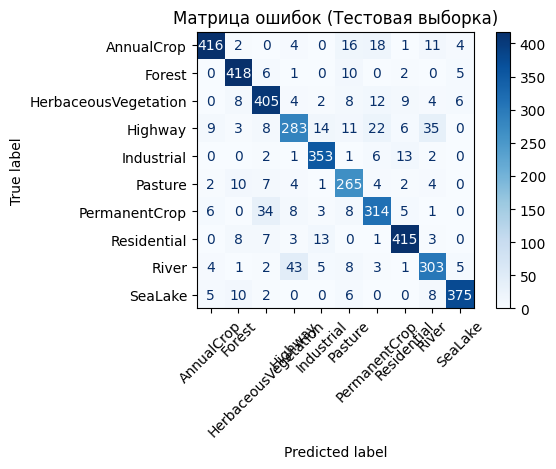


Ошибок на тесте: 503 из 4050


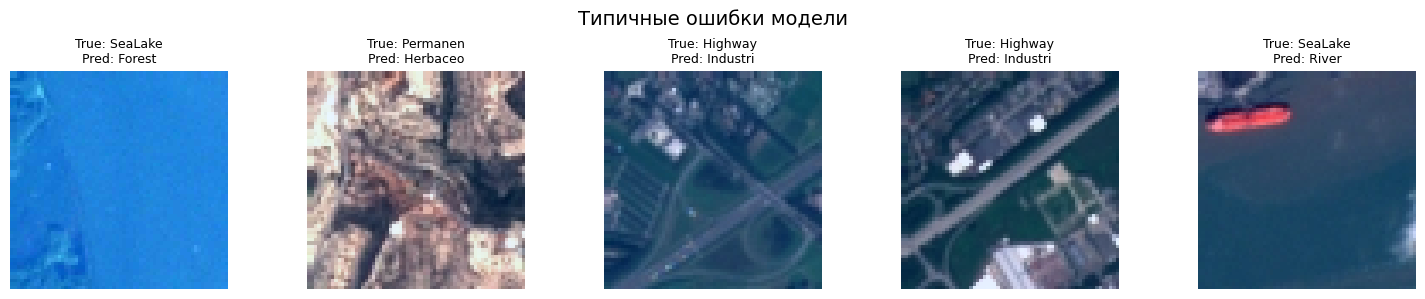

In [11]:
LOSS_FN = nn.CrossEntropyLoss()

metrics_custom = evaluate(custom_model, test_loader, LOSS_FN, NUM_CLASSES)
metrics_transfer = evaluate(transfer_model, test_loader, LOSS_FN, NUM_CLASSES)

print("\n=== Сравнение моделей на тесте ===")
print(f"{'Модель':<20} | {'Test Acc':<10} | {'Test F1':<10} | {'Параметров':<12} | {'Время, с':<8}")
print("-" * 75)
print(f"{'CNN с нуля':<20} | {metrics_custom['acc']:<10.4f} | {metrics_custom['macro_f1']:<10.4f} | {sum(p.numel() for p in custom_model.parameters()):<12} | {time_custom:<8.1f}")
print(f"{'Transfer learning':<20} | {metrics_transfer['acc']:<10.4f} | {metrics_transfer['macro_f1']:<10.4f} | {sum(p.numel() for p in transfer_model.parameters()):<12} | {time_transfer:<8.1f}")

best_model = transfer_model if best_f1_transfer >= best_f1_custom else custom_model
model_name = "Transfer learning" if best_model is transfer_model else "CNN с нуля"
print(f"\nЛучшая модель: {model_name}")

# Матрица ошибок
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    ys, ps = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        ps.append(model(xb).argmax(1).cpu())
        ys.append(yb)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

y_true, y_pred = predict_all(best_model, test_loader)
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(12, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Матрица ошибок (Тестовая выборка)")
plt.tight_layout()
plt.show()

# Анализ ошибок
wrong_idx = np.where(y_pred != y_true)[0]
print(f"\nОшибок на тесте: {len(wrong_idx)} из {len(y_true)}")

plt.figure(figsize=(15, 3))
for j, i in enumerate(wrong_idx[:5]):
    img_tensor, true_label = test_ds[i]
    with torch.no_grad():
        pred = best_model(img_tensor.unsqueeze(0).to(device)).argmax(1).item()

    plt.subplot(1, 5, j + 1)
    img = img_tensor.permute(1, 2, 0).numpy()
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    plt.imshow(img)
    plt.title(f"True: {CLASS_NAMES[true_label][:8]}\nPred: {CLASS_NAMES[pred][:8]}", fontsize=9)
    plt.axis("off")
plt.suptitle("Типичные ошибки модели", fontsize=14)
plt.tight_layout()
plt.show()

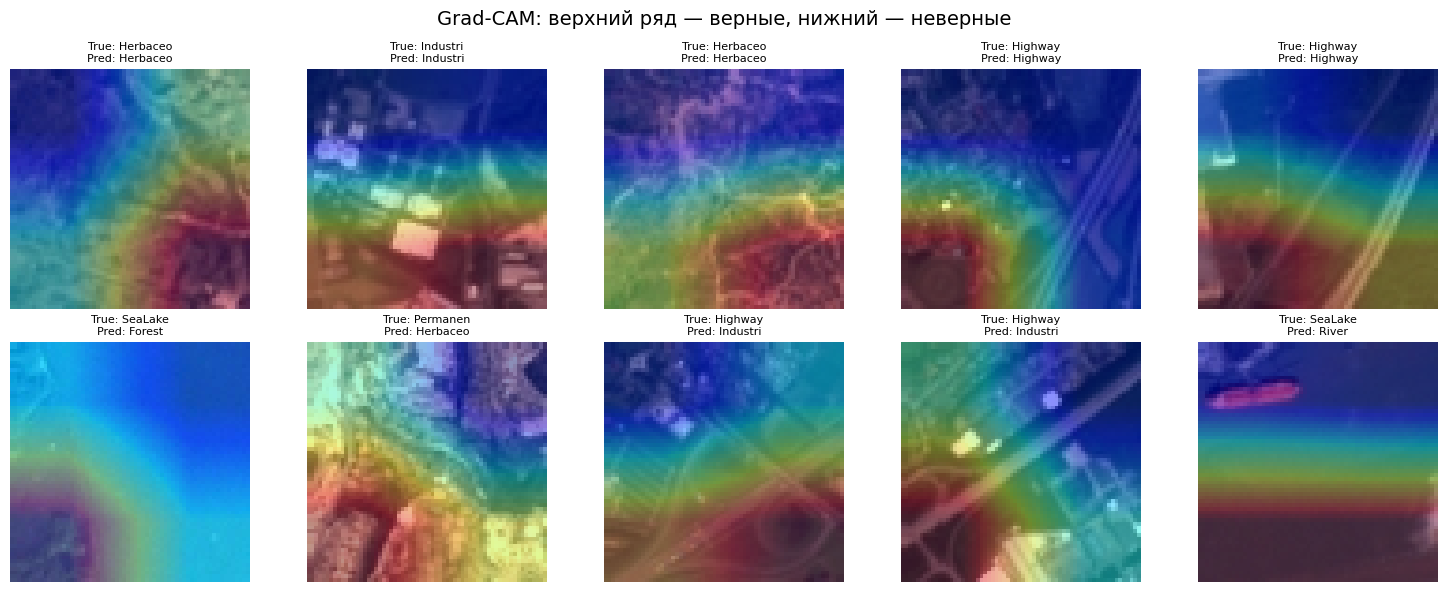

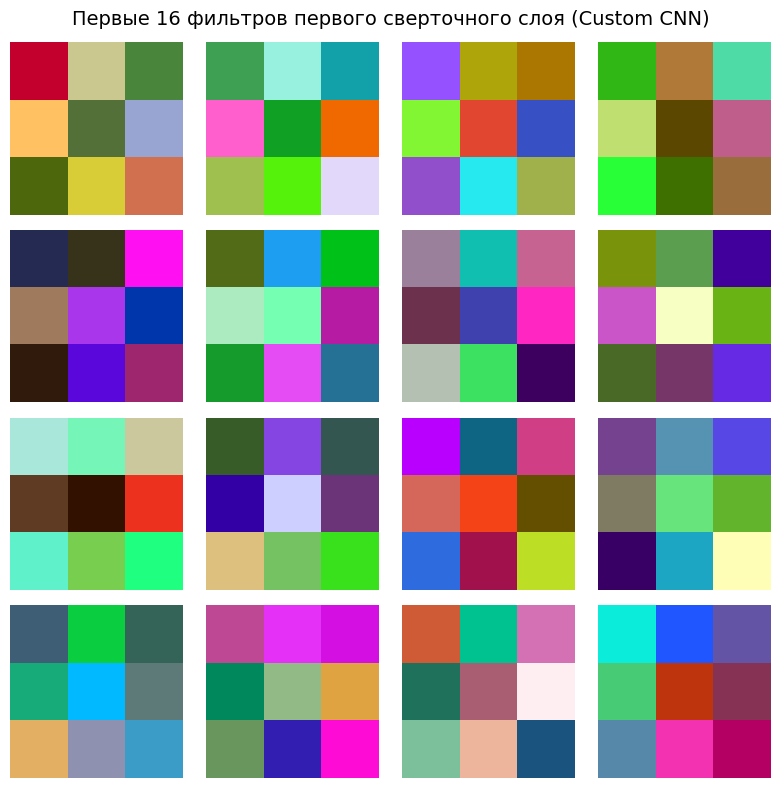

In [12]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def __call__(self, image, class_idx=None):
        self.model.zero_grad()
        logits = self.model(image)
        if class_idx is None:
            class_idx = logits.argmax(1).item()
        score = logits[0, class_idx]
        score.backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam[0, 0].cpu().numpy(), class_idx

def resize_heatmap(heatmap, size):
    cam = torch.from_numpy(heatmap)[None, None]
    cam = torch.nn.functional.interpolate(cam, size=size, mode="bilinear", align_corners=False)
    return cam[0, 0].numpy()

def get_target_layer(model, backbone):
    if isinstance(model, CustomCNN):
        return model.features[-1].conv
    if backbone == "resnet50":
        return model.backbone.layer4[-1]
    return model.backbone.conv_head # Для mobilenetv2_100

target_layer = get_target_layer(best_model, SPEC["backbone"])
gradcam = GradCAM(best_model, target_layer)

correct_idx = np.where(y_pred == y_true)[0][:5]
wrong_idx_cam = np.where(y_pred != y_true)[0][:5]

plt.figure(figsize=(15, 6))
for col, idx in enumerate([*correct_idx, *wrong_idx_cam]):
    img_tensor, true_label = test_ds[idx]
    img_tensor = img_tensor.unsqueeze(0).to(device)
    heatmap, pred = gradcam(img_tensor)

    img = img_tensor[0].cpu().permute(1, 2, 0).numpy()
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)

    plt.subplot(2, 5, col + 1)
    plt.imshow(img)
    plt.imshow(resize_heatmap(heatmap, img.shape[:2]), cmap="jet", alpha=0.4)
    plt.title(f"True: {CLASS_NAMES[true_label][:8]}\nPred: {CLASS_NAMES[pred][:8]}", fontsize=8)
    plt.axis("off")
plt.suptitle("Grad-CAM: верхний ряд — верные, нижний — неверные", fontsize=14)
plt.tight_layout()
plt.show()

# Фильтры первого слоя оригинальной CNN
filters = custom_model.features[0].conv.weight.detach().cpu()
plt.figure(figsize=(8, 8))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    f = filters[i]
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)
    plt.imshow(f.permute(1, 2, 0).numpy())
    plt.axis("off")
plt.suptitle("Первые 16 фильтров первого сверточного слоя (Custom CNN)", fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
# 1. Сохранение model.pt
CHECKPOINT_PATH = "model.pt"
def save_model(path, model, spec, classes, metrics):
    is_transfer = isinstance(model, TransferModel)
    torch.save({
        "model_state": model.state_dict(),
        "arch": "transfer" if is_transfer else "custom",
        "variant": VARIANT,
        "dataset": spec["name"],
        "backbone": spec["backbone"] if is_transfer else None,
        "classes": classes,
        "img_size": spec["img_size"],
        "grayscale": spec["grayscale"],
        "metrics": metrics,
    }, path)

best_metrics = metrics_transfer if best_model is transfer_model else metrics_custom
save_model(CHECKPOINT_PATH, best_model.cpu(), SPEC, CLASS_NAMES, {
    "test_accuracy": float(best_metrics["acc"]),
    "test_macro_f1": float(best_metrics["macro_f1"]),
})
print(f" Веса сохранены в {CHECKPOINT_PATH}")



 Веса сохранены в model.pt
